<a href="https://colab.research.google.com/github/riyagupta2455/working-capital-benchmark/blob/main/working_capital_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Working Capital Benchmarking: How Much Cash Is Stuck in the Cash Conversion Cycle?

**Question this project answers:** across a peer set of companies in **any industry** (pick a preset in the config cell or type your own tickers; the default case study is US packaged food & beverage), who runs working capital best, how has that changed over ~10 years, and how much cash could a laggard free up by closing the gap to its peers?

**Why it matters:** working capital is the cheapest source of funding a company has. Every day taken out of the cash conversion cycle (CCC) releases cash that can pay down debt, fund buybacks or go into capex, with no new financing. CFOs, FP&A, treasury, consultants (working-capital diagnostics are a staple engagement) and equity analysts all look at this.

**What the notebook does**

1. Pulls 10 years of audited 10-K data straight from **SEC EDGAR XBRL** (free, no API key)
2. Builds DSO, DIO, DPO, CCC and net working capital as % of sales for each company
3. Benchmarks every company against the peer median and top quartile
4. Sizes the **cash release opportunity** for a target company, by lever
5. Runs a sensitivity: cash freed per day of improvement
6. Shows **seasonality** from quarterly 10-Q data: peak vs trough cash needs
7. Links the cycle to **FCF conversion and ROIC**
8. Exports everything to Excel

| Metric | Formula | Read as |
|---|---|---|
| DSO (days sales outstanding) | avg receivables / revenue × 365 | how long customers take to pay |
| DIO (days inventory outstanding) | avg inventory / COGS × 365 | how long stock sits before it's sold |
| DPO (days payables outstanding) | avg payables / COGS × 365 | how long we take to pay suppliers |
| **CCC** | DSO + DIO − DPO | days of cash tied up in operations |

Lower (even negative) CCC = the business is partly funded by its suppliers.

## 1. Setup and configuration

Pick an **industry preset** from the dropdown, or choose `Custom` and type any US-listed tickers. Leave `TARGET` blank to automatically size the opportunity for the peer group's laggard (the company with the longest cash conversion cycle).

SEC asks every API user to identify themselves, so put your name and email in `USER_AGENT`.

> Works for any company that files 10-Ks with the SEC (US-listed, plus some foreign filers that use US GAAP). Banks and insurers are excluded on purpose: the cash conversion cycle doesn't mean much for them.

In [54]:
!pip -q install openpyxl

import time, json, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- CONFIG ----------------
USER_AGENT = "Your Name your.email@example.com"   # required by SEC: replace with your own

INDUSTRY = "Packaged food & beverage"  #@param ["Packaged food & beverage", "Household & personal care", "Big-box & grocery retail", "Apparel & footwear", "Home improvement & specialty retail", "Pharma & biotech", "Semiconductors", "Tech hardware", "Software (no inventory)", "Industrial machinery", "Autos", "Airlines", "Custom"]
CUSTOM_PEERS = "WMT, TGT, COST, KR"    #@param {type:"string"}
TARGET = ""                            #@param {type:"string"}
N_YEARS = 10                           #@param {type:"integer"}
BENCHMARK = "median"                   #@param ["median", "top_quartile"]
EXCLUDE_ACCRUED_AP = True              #@param {type:"boolean"}
DAYS = 365

INDUSTRY_PEERS = {
    "Packaged food & beverage":            ["PEP", "KO", "MDLZ", "KDP", "GIS", "HSY", "KHC", "CAG", "CPB", "SJM", "HRL"],
    "Household & personal care":           ["PG", "CL", "KMB", "CHD", "CLX", "EL", "COTY"],
    "Big-box & grocery retail":            ["WMT", "TGT", "COST", "KR", "DG", "DLTR", "BJ", "ACI"],
    "Apparel & footwear":                  ["NKE", "LULU", "TJX", "ROST", "GAP", "PVH", "RL", "VFC", "DECK"],
    "Home improvement & specialty retail": ["HD", "LOW", "BBY", "TSCO", "WSM", "ULTA"],
    "Pharma & biotech":                    ["PFE", "MRK", "JNJ", "ABBV", "LLY", "BMY", "AMGN", "GILD"],
    "Semiconductors":                      ["NVDA", "AMD", "INTC", "QCOM", "TXN", "AVGO", "MU", "ADI"],
    "Tech hardware":                       ["AAPL", "DELL", "HPQ", "HPE", "CSCO", "ANET", "SMCI"],
    "Software (no inventory)":             ["MSFT", "ORCL", "CRM", "ADBE", "NOW", "INTU", "WDAY", "ADSK"],
    "Industrial machinery":                ["CAT", "DE", "CMI", "PCAR", "ETN", "PH", "EMR", "DOV"],
    "Autos":                               ["GM", "F", "TSLA"],
    "Airlines":                            ["DAL", "UAL", "AAL", "LUV", "ALK", "JBLU"],
}
DEFAULT_TARGET = {"Packaged food & beverage": "KHC"}   # optional: a fixed target per preset

if INDUSTRY == "Custom":
    PEERS = [t.strip().upper() for t in CUSTOM_PEERS.split(",") if t.strip()]
else:
    PEERS = INDUSTRY_PEERS[INDUSTRY]
TARGET = TARGET.strip().upper() or DEFAULT_TARGET.get(INDUSTRY, "")
# ----------------------------------------

HEADERS = {"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"}
assert "example.com" not in USER_AGENT, "Set USER_AGENT to your own name + email first (SEC requirement)."
assert len(PEERS) >= 3, "Benchmarking needs at least 3 companies."
print(f"Industry: {INDUSTRY}\nPeers: {', '.join(PEERS)}\nTarget: {TARGET or '(auto: the laggard)'}")

Industry: Packaged food & beverage
Peers: PEP, KO, MDLZ, KDP, GIS, HSY, KHC, CAG, CPB, SJM, HRL
Target: KHC


## 2. Pull the data from SEC EDGAR

Two endpoints:
- `company_tickers.json` maps tickers to CIK numbers (SEC's company ID)
- `companyfacts/CIK##########.json` returns every XBRL fact the company has ever reported

**The messy part (and a good interview talking point):** companies don't all use the same XBRL tag. Coca-Cola and PepsiCo label receivables differently, some report `Revenues` and others `RevenueFromContractWithCustomer...`. So for each line item we try a ranked list of tags and take the first one that has data for each year.

In [55]:
def get_json(url, retries=3):
    for i in range(retries):
        r = requests.get(url, headers=HEADERS, timeout=30)
        if r.status_code == 200:
            return r.json()
        time.sleep(1 + i)
    r.raise_for_status()

tickers = get_json("https://www.sec.gov/files/company_tickers.json")
TICKER_TO_CIK = {v["ticker"]: str(v["cik_str"]).zfill(10) for v in tickers.values()}
TICKER_TO_NAME = {v["ticker"]: v["title"] for v in tickers.values()}

missing = [t for t in PEERS if t not in TICKER_TO_CIK]
if missing:
    print("Not found on EDGAR (delisted/acquired?), dropping:", missing)
PEERS = [t for t in PEERS if t in TICKER_TO_CIK]

facts = {}
for t in PEERS:
    facts[t] = get_json(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{TICKER_TO_CIK[t]}.json")
    time.sleep(0.15)   # SEC allows max 10 requests/sec
print(f"Downloaded company facts for {len(facts)} companies")

Downloaded company facts for 11 companies


### Tag map and extraction logic

- **Flow items** (revenue, COGS) cover a period: keep only ~1-year durations from 10-K filings.
- **Stock items** (receivables, inventory, payables) are balances at a date: keep 10-K values at the fiscal year-end.
- If a number was restated in a later 10-K, the latest filing wins.

In [56]:
TAGS = {
    "revenue": ["RevenueFromContractWithCustomerExcludingAssessedTax", "Revenues",
                "SalesRevenueNet", "SalesRevenueGoodsNet", "RevenueFromContractWithCustomerIncludingAssessedTax"],
    "cogs":    ["CostOfGoodsAndServicesSold", "CostOfRevenue", "CostOfGoodsSold",
                "CostOfGoodsAndServiceExcludingDepreciationDepletionAndAmortization", "CostOfServices",
                # proxies for companies with no cost-of-sales line (e.g. airlines): flagged in the quality check
                "CostsAndExpenses", "OperatingCostsAndExpenses", "OperatingExpenses"],
    "receivables": ["AccountsReceivableNetCurrent", "AccountsAndNotesReceivableNetCurrent",
                    "AccountsNotesAndLoansReceivableNetCurrent", "ReceivablesNetCurrent",
                    "AccountsAndOtherReceivablesNetCurrent", "CreditAndDebitCardReceivablesAtCarryingValue"],
    "inventory":   ["InventoryNet", "InventoryGross", "InventoryFinishedGoodsNetOfReserves",
                    "RetailRelatedInventoryMerchandise"],
    "payables":    ["AccountsPayableCurrent", "AccountsPayableTradeCurrent",
                    "AccountsPayableAndAccruedLiabilitiesCurrent"],
}
FLOW_ITEMS = {"revenue", "cogs"}
NOT_A_BALANCE = ("Deferred", "Increase", "WriteDown", "Reserve", "Expense", "Income", "Purchase", "Recall", "Percentage", "Effect", "Capitalized")

def reports_any_inventory(cf):
    # True if the company files ANY inventory balance tag, even one we don't map (so we don't wrongly set DIO to 0)
    g = cf["facts"].get("us-gaap", {})
    return any("Inventor" in k and not any(w in k for w in NOT_A_BALANCE)
               and any(e["form"] == "10-K" for e in g[k]["units"].get("USD", [])) for k in g)

def tag_series(cf, tag, flow):
    # Return {fiscal_year_end_date: value} for one XBRL tag from 10-K filings.
    node = cf["facts"].get("us-gaap", {}).get(tag)
    if not node or "USD" not in node["units"]:
        return pd.Series(dtype=float)
    df = pd.DataFrame(node["units"]["USD"])
    df = df[df["form"].isin(["10-K", "10-K/A"])].copy()
    df["end"] = pd.to_datetime(df["end"])
    if flow:
        if "start" not in df:
            return pd.Series(dtype=float)
        df["days"] = (df["end"] - pd.to_datetime(df["start"])).dt.days
        df = df[df["days"].between(340, 380)]
    df = df.sort_values("filed").drop_duplicates("end", keep="last")   # latest filing wins
    return df.set_index("end")["val"].astype(float)

def item_series(cf, item):
    # Combine ranked tags: first tag with a value for a given date wins. Also record which tag was used.
    vals, srcs = {}, {}
    for tag in TAGS[item]:
        for d, v in tag_series(cf, tag, item in FLOW_ITEMS).items():
            if d not in vals:
                vals[d], srcs[d] = v, tag
    return pd.Series(vals, dtype=float).sort_index(), pd.Series(srcs, dtype=object).sort_index()

rows, tag_log, no_inventory, derived_inventory, low_receivables = [], [], [], [], []
for t, cf in facts.items():
    series = {}
    for item in TAGS:
        s, src = item_series(cf, item)
        series[item] = s
        if item == "payables":
            ap_src = src
        for d, tg in src.items():
            tag_log.append({"ticker": t, "item": item, "fy_end": d, "tag": tg})
    if series["inventory"].empty:          # LIFO reporters (e.g. Kroger): inventory = FIFO cost - LIFO reserve
        fifo, lifo = tag_series(cf, "FIFOInventoryAmount", False), tag_series(cf, "InventoryLIFOReserve", False)
        if not fifo.empty:
            series["inventory"] = fifo - lifo.reindex(fifo.index).fillna(0)
            derived_inventory.append(t)
    fy_ends = series["revenue"].index           # fiscal year-ends defined by annual revenue
    df = pd.DataFrame({k: v.reindex(fy_ends) for k, v in series.items()})
    if EXCLUDE_ACCRUED_AP:   # blank out payables that include accruals, so DPO/CCC isn't overstated
        bad = ap_src[ap_src == "AccountsPayableAndAccruedLiabilitiesCurrent"].index
        df.loc[df.index.isin(bad), "payables"] = np.nan
    if series["inventory"].empty and not reports_any_inventory(cf):   # e.g. software: no inventory at all -> DIO = 0
        df["inventory"] = 0.0
        no_inventory.append(t)
    if df["receivables"].notna().mean() < 0.5:   # e.g. cash-and-card retailers that rarely report trade receivables
        df["receivables"] = df["receivables"].fillna(0.0)
        low_receivables.append(t)
    df["ticker"] = t
    rows.append(df.rename_axis("fy_end").reset_index())

raw = pd.concat(rows, ignore_index=True)
# fiscal year label = calendar year in which most of the fiscal year falls
# (so Walmart's year ending Jan-2025 and General Mills' ending May-2025 both line up with calendar 2024 peers)
raw["fy"] = (raw["fy_end"] - pd.Timedelta(days=182)).dt.year
raw = raw.sort_values(["ticker", "fy"]).drop_duplicates(["ticker", "fy"], keep="last")
raw = raw[raw["fy"] > raw["fy"].max() - N_YEARS - 1]   # keep one extra year for averaging
tag_log = pd.DataFrame(tag_log)

print("Coverage (non-missing years per item):")
display(raw.groupby("ticker")[list(TAGS)].count())

Coverage (non-missing years per item):


,revenue,cogs,receivables,inventory,payables
ticker,,,,,
CAG,10,10,10,10,10
CPB,11,11,11,11,11
GIS,10,10,10,10,10
HRL,10,10,10,10,10
HSY,10,10,10,10,10
KDP,10,10,10,10,10
KHC,10,10,10,10,10
KO,10,10,10,10,10
MDLZ,10,10,10,10,10


### Data quality check
Always look at which tag fed each number. `AccountsPayableAndAccruedLiabilitiesCurrent` lumps accruals in with trade payables and will **overstate DPO**. Flag it rather than silently trusting it.

With `EXCLUDE_ACCRUED_AP = True` (the default) those company-years are blanked out, so they show as gaps in the heatmap rather than as fake improvements. Because DPO uses average balances, the year right after an excluded year also drops out.

Two more checks matter once you leave consumer goods:
- **No inventory** (software, services): DIO is set to 0 rather than treated as missing.
- **No cost-of-sales line** (airlines, some service businesses): total operating costs are used as a proxy for COGS, so DIO/DPO are on a different basis. These are flagged below.

In [57]:
used = tag_log.groupby(["ticker", "item"])["tag"].agg(lambda x: x.value_counts().index[0]).unstack()
display(used)

flagged = tag_log[tag_log["tag"] == "AccountsPayableAndAccruedLiabilitiesCurrent"]["ticker"].unique()
if len(flagged):
    yrs = (tag_log[tag_log["tag"] == "AccountsPayableAndAccruedLiabilitiesCurrent"]
           .groupby("ticker")["fy_end"].apply(lambda s: sorted(s.dt.year.tolist())).to_dict())
    if EXCLUDE_ACCRUED_AP:
        print("Excluded from DPO/CCC (payables include accrued liabilities), by fiscal year-end:", yrs)
    else:
        print("Caution: payables include accrued liabilities ->", yrs, "-> DPO overstated in those years")

if no_inventory:
    print("No inventory reported (DIO set to 0):", no_inventory)
if derived_inventory:
    print("Inventory derived as FIFO cost minus LIFO reserve:", derived_inventory)
if low_receivables:
    print("Receivables rarely reported (missing years treated as 0):", low_receivables)
proxy = tag_log[(tag_log["item"] == "cogs") & tag_log["tag"].isin(["CostsAndExpenses", "OperatingCostsAndExpenses", "OperatingExpenses"])]
if len(proxy):
    print("COGS proxied by total operating costs for:", sorted(proxy["ticker"].unique()), "-> compare DIO/DPO with care")

item,cogs,inventory,payables,receivables,revenue
ticker,,,,,
CAG,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,ReceivablesNetCurrent,RevenueFromContractWithCustomerExcludingAssess...
CPB,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,Revenues
GIS,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,ReceivablesNetCurrent,RevenueFromContractWithCustomerExcludingAssess...
HRL,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,SalesRevenueNet
HSY,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,RevenueFromContractWithCustomerExcludingAssess...
KDP,CostOfGoodsSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,SalesRevenueNet
KHC,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableTradeCurrent,AccountsReceivableNetCurrent,RevenueFromContractWithCustomerIncludingAssess...
KO,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableTradeCurrent,AccountsReceivableNetCurrent,Revenues
MDLZ,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,Revenues


Excluded from DPO/CCC (payables include accrued liabilities), by fiscal year-end: {'KO': [2008], 'PEP': [2008]}


## 3. Build the metrics

Using **average balances** (opening + closing ÷ 2) instead of year-end balances. Year-end balances get window-dressed (companies push collections and delay payments around 31 Dec), so averages are a fairer read. The first year of each company is dropped because it has no opening balance.

In [58]:
def build_metrics(raw):
    d = raw.sort_values(["ticker", "fy"]).copy()
    for b in ["receivables", "inventory", "payables"]:
        d[f"avg_{b}"] = d.groupby("ticker")[b].transform(lambda s: (s + s.shift(1)) / 2)
    d["DSO"] = d["avg_receivables"] / d["revenue"] * DAYS
    d["DIO"] = d["avg_inventory"] / d["cogs"] * DAYS
    d["DPO"] = d["avg_payables"] / d["cogs"] * DAYS
    d["CCC"] = d["DSO"] + d["DIO"] - d["DPO"]
    d["trade_wc"] = d["receivables"] + d["inventory"] - d["payables"]
    d["trade_wc_pct_sales"] = d["trade_wc"] / d["revenue"] * 100
    d["gross_margin_pct"] = (1 - d["cogs"] / d["revenue"]) * 100
    return d.dropna(subset=["CCC"])

m = build_metrics(raw)

# drop companies without enough usable history
yrs_per_co = m.groupby("ticker")["fy"].nunique()
thin = yrs_per_co[yrs_per_co < 3].index.tolist()
if thin:
    print("Dropped (fewer than 3 usable years, usually missing line items):", thin)
    m = m[~m["ticker"].isin(thin)]

# latest year that at least 75% of the peer group has reported
cos_per_year = m.groupby("fy")["ticker"].nunique()
LATEST = int(cos_per_year[cos_per_year >= 0.75 * m["ticker"].nunique()].index.max())
print(f"Metrics for {m['ticker'].nunique()} companies, FY{m['fy'].min()}-FY{m['fy'].max()}; common latest year = FY{LATEST}")

latest = m[m["fy"] == LATEST].set_index("ticker")
if TARGET not in latest.index:
    if TARGET:
        print(f"{TARGET} has no FY{LATEST} data in this peer set, so picking the laggard instead.")
    TARGET = latest["CCC"].idxmax()        # auto: the company with the longest cash cycle
print(f"Target for opportunity sizing: {TARGET}")
cols = ["revenue", "DSO", "DIO", "DPO", "CCC", "trade_wc_pct_sales", "gross_margin_pct"]
view = latest[cols].copy()
view["revenue"] = view["revenue"] / 1e9
view = view.rename(columns={"revenue": "revenue_$bn", "trade_wc_pct_sales": "tradeWC_%sales", "gross_margin_pct": "GM_%"})
view = view.sort_values("CCC")
stats = view[["DSO", "DIO", "DPO", "CCC"]].agg(["median"]).rename(index={"median": "PEER MEDIAN"})
display(pd.concat([view, stats]))

Metrics for 11 companies, FY2017-FY2026; common latest year = FY2025
Target for opportunity sizing: KHC


,revenue_$bn,DSO,DIO,DPO,CCC,tradeWC_%sales,GM_%
MDLZ,38.5,36.8,54.5,129.4,-38.1,-4.7,28.4
KDP,16.6,34.9,72.8,143.5,-35.9,2.5,54.2
GIS,18.4,34.1,57.1,115.5,-24.3,-0.9,33.6
PEP,93.9,42.4,47.3,96.2,-6.5,6.0,54.1
KO,47.9,25.2,90.8,110.3,5.7,3.8,61.6
KHC,24.9,32.2,71.8,93.2,10.8,4.5,33.3
SJM,9.1,25.7,70.9,74.7,21.8,6.7,33.5
CPB,10.3,20.1,71.9,67.6,24.4,6.2,30.4
HSY,11.7,23.9,63.0,56.7,30.2,7.7,33.5
CAG,11.3,23.1,84.1,66.0,41.2,9.3,23.9


## 4. Peer benchmarking visuals

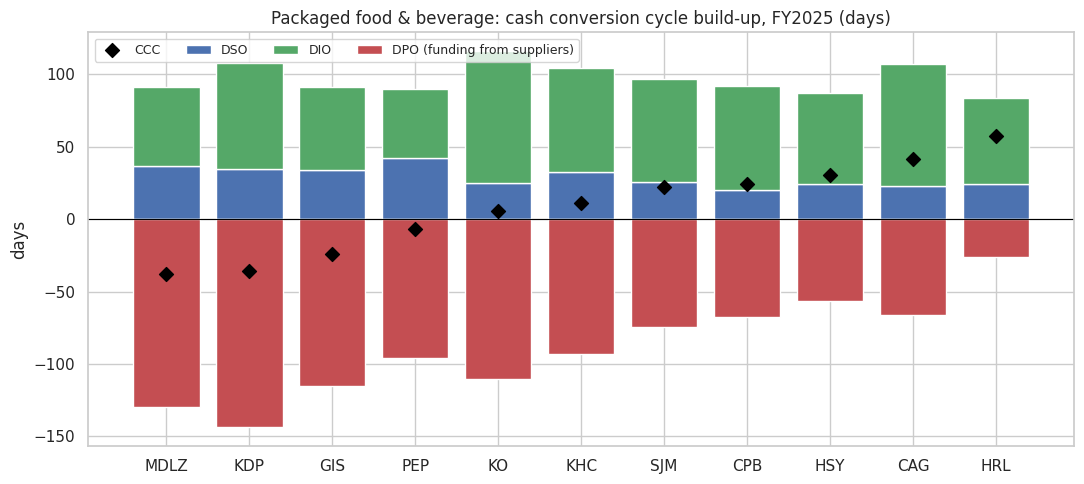

In [59]:
# 4a. CCC decomposition, latest year
order = latest.sort_values("CCC").index
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(order, latest.loc[order, "DSO"], label="DSO", color="#4C72B0")
ax.bar(order, latest.loc[order, "DIO"], bottom=latest.loc[order, "DSO"], label="DIO", color="#55A868")
ax.bar(order, -latest.loc[order, "DPO"], label="DPO (funding from suppliers)", color="#C44E52")
ax.scatter(order, latest.loc[order, "CCC"], color="black", zorder=5, label="CCC", s=50, marker="D")
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"{INDUSTRY}: cash conversion cycle build-up, FY{LATEST} (days)")
ax.set_ylabel("days"); ax.legend(loc="upper left", ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

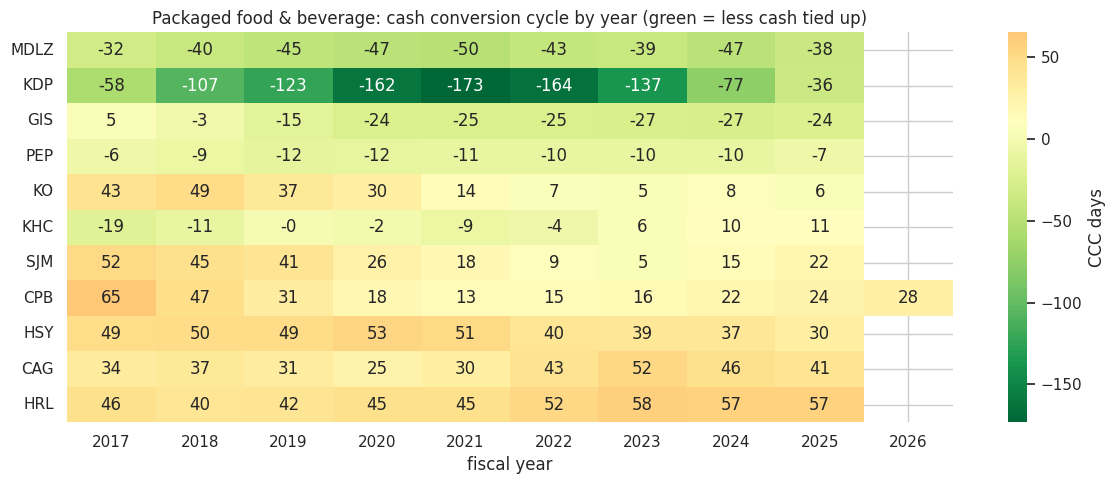

In [60]:
# 4b. CCC heatmap over time: who improved, who slipped
pivot = m.pivot_table(index="ticker", columns="fy", values="CCC")
pivot = pivot.loc[pivot[LATEST].sort_values().index]
plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn_r", center=pivot.stack().median(), cbar_kws={"label": "CCC days"})
plt.title(f"{INDUSTRY}: cash conversion cycle by year (green = less cash tied up)")
plt.xlabel("fiscal year"); plt.ylabel("")
plt.tight_layout(); plt.show()

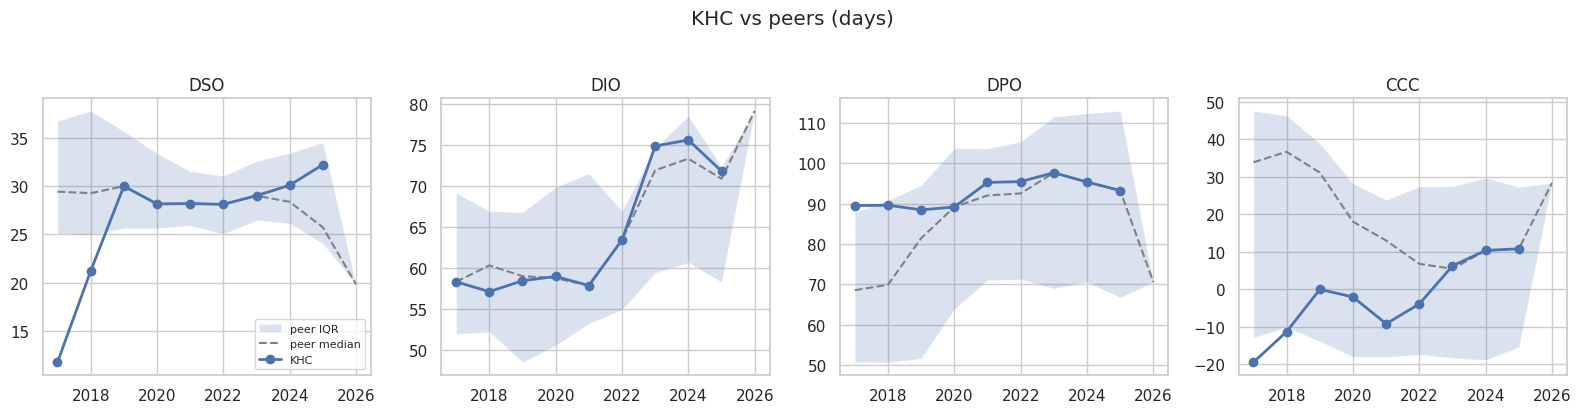

In [61]:
# 4c. Target vs peer median and interquartile band, each component
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)
for ax, metric in zip(axes, ["DSO", "DIO", "DPO", "CCC"]):
    g = m.groupby("fy")[metric]
    ax.fill_between(g.median().index, g.quantile(0.25), g.quantile(0.75), alpha=0.2, label="peer IQR")
    ax.plot(g.median(), "--", color="grey", label="peer median")
    tgt = m[m["ticker"] == TARGET].set_index("fy")[metric]
    ax.plot(tgt, marker="o", lw=2, label=TARGET)
    ax.set_title(metric)
axes[0].legend(fontsize=8)
fig.suptitle(f"{TARGET} vs peers (days)", y=1.03)
plt.tight_layout(); plt.show()

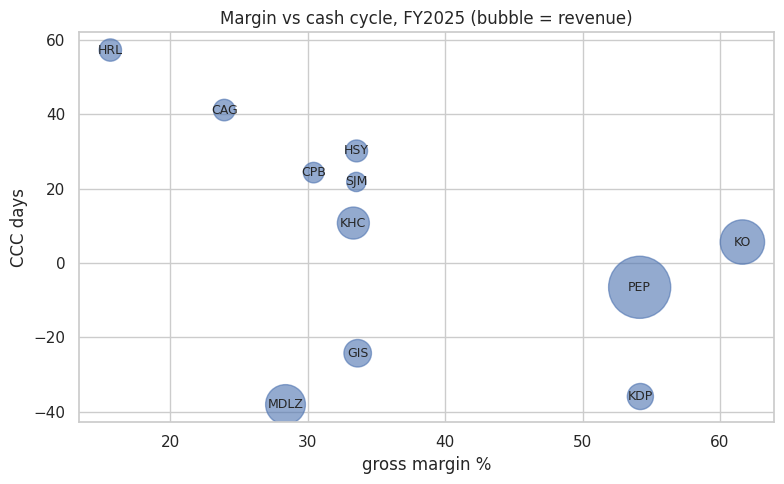

In [62]:
# 4d. Does scale or margin explain working capital? (quick look, not a causal claim)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(latest["gross_margin_pct"], latest["CCC"], s=2000 * latest["revenue"] / latest["revenue"].max(), alpha=0.6)
for t, r in latest.iterrows():
    ax.annotate(t, (r["gross_margin_pct"], r["CCC"]), fontsize=9, ha="center", va="center")
ax.set_xlabel("gross margin %"); ax.set_ylabel("CCC days")
ax.set_title(f"Margin vs cash cycle, FY{LATEST} (bubble = revenue)")
plt.tight_layout(); plt.show()

## 5. Sizing the cash opportunity for the target

For each lever, compare the target to the benchmark and convert the day gap into dollars:

- Receivables: `(DSO_target − DSO_benchmark) × revenue / 365`
- Inventory: `(DIO_target − DIO_benchmark) × COGS / 365`
- Payables: `(DPO_benchmark − DPO_target) × COGS / 365` (here the benchmark is *higher* days)

Only gaps where the target is worse count. If it's already better than peers, the opportunity for that lever is zero, not negative.

In [63]:
def benchmark(series, kind, higher_is_better=False):
    if kind == "median":
        return series.median()
    q = 0.75 if higher_is_better else 0.25
    return series.quantile(q)

def cash_opportunity(ticker, year=LATEST, kind=BENCHMARK):
    peers = m[(m["fy"] == year) & (m["ticker"] != ticker)]
    t = m[(m["fy"] == year) & (m["ticker"] == ticker)].iloc[0]
    out = []
    for metric, base, hib, label in [("DSO", "revenue", False, "Receivables (collect faster)"),
                                     ("DIO", "cogs", False, "Inventory (hold less)"),
                                     ("DPO", "cogs", True, "Payables (pay later)")]:
        bm = benchmark(peers[metric], kind, hib)
        gap = (bm - t[metric]) if hib else (t[metric] - bm)
        cash = max(gap, 0) * t[base] / DAYS
        out.append({"lever": label, "target_days": t[metric], "benchmark_days": bm,
                    "gap_days": gap, "cash_release_$m": cash / 1e6})
    df = pd.DataFrame(out)
    return df, t

opp, t_row = cash_opportunity(TARGET)
total = opp["cash_release_$m"].sum()
display(opp)
print(f"\n{TARGET}: closing the gap to peer {BENCHMARK} would release about ${total:,.0f}m of cash "
      f"({total*1e6 / t_row['revenue']*100:.1f}% of revenue).")

,lever,target_days,benchmark_days,gap_days,cash_release_$m
0,Receivables (collect faster),32.2,25.4,6.8,462.6
1,Inventory (hold less),71.8,66.9,4.8,221.0
2,Payables (pay later),93.2,85.5,-7.8,0.0



KHC: closing the gap to peer median would release about $684m of cash (2.7% of revenue).


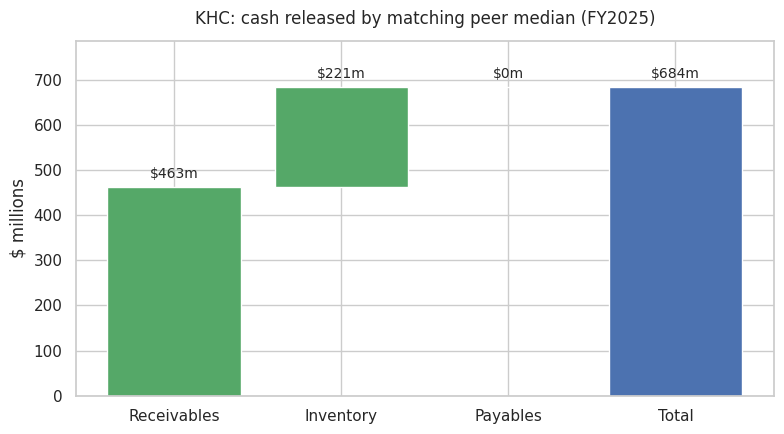

In [64]:
# Waterfall: where the cash comes from
vals = opp["cash_release_$m"].tolist()
labels = [l.split(" (")[0] for l in opp["lever"]] + ["Total"]
starts = np.concatenate([[0], np.cumsum(vals)[:-1]])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(labels[:-1], vals, bottom=starts, color="#55A868")
ax.bar(labels[-1], total, color="#4C72B0")
pad = max(total, 1) * 0.02
for i, v in enumerate(vals + [total]):
    top = starts[i] + v if i < len(vals) else total
    ax.text(i, top + pad, f"${v:,.0f}m", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, max(total, 1) * 1.15)   # headroom so value labels don't run into the title
ax.set_ylabel("$ millions")
ax.set_title(f"{TARGET}: cash released by matching peer {BENCHMARK} (FY{LATEST})", pad=12)
plt.tight_layout(); plt.show()

In [65]:
# Run the same sizing for every company: the peer-wide picture
summary = []
for tk in latest.index:
    for kind in ["median", "top_quartile"]:
        o, r = cash_opportunity(tk, kind=kind)
        summary.append({"ticker": tk, "benchmark": kind, "cash_release_$m": o["cash_release_$m"].sum(),
                        "pct_revenue": o["cash_release_$m"].sum() * 1e6 / r["revenue"] * 100})
opp_all = pd.DataFrame(summary).pivot(index="ticker", columns="benchmark", values=["cash_release_$m", "pct_revenue"])
display(opp_all.sort_values(("cash_release_$m", "median"), ascending=False))

cash_release_$m              pct_revenue             
benchmark          median top_quartile      median top_quartile
ticker                                                         
PEP               4,374.8      6,879.3         4.7          7.3
HRL               1,916.8      2,483.6        15.8         20.5
MDLZ              1,203.3      1,359.8         3.1          3.5
KO                1,202.5      1,845.7         2.5          3.8
CAG               1,078.1      1,753.6         9.6         15.5
HSY                 808.7      1,336.8         6.9         11.4
KHC                 683.5      2,161.7         2.7          8.7
CPB                 626.2      1,187.6         6.1         11.6
KDP                 551.0        811.0         3.3          4.9
GIS                 437.5        512.4         2.4          2.8
SJM                 386.1        911.0         4.3         10.1

## 6. Sensitivity: what is one day worth?

Management rarely closes the whole gap at once. This shows the cash freed for each day of improvement on each lever, which is how a CFO would frame a target ("take 5 days out of DIO next year").

In [66]:
day_value = pd.DataFrame({
    "1 day DSO ($m)": latest["revenue"] / DAYS / 1e6,
    "1 day DIO/DPO ($m)": latest["cogs"] / DAYS / 1e6,
})
display(day_value.sort_values("1 day DSO ($m)", ascending=False))

tr = latest.loc[TARGET]
grid = pd.DataFrame({f"{d} days CCC": [d * tr["cogs"] / DAYS / 1e6] for d in [5, 10, 15, 20]}, index=[TARGET])
print("Cash from cutting CCC via DIO/DPO levers ($m):"); display(grid)

,1 day DSO ($m),1 day DIO/DPO ($m)
ticker,,
PEP,257.3,118.0
KO,131.3,50.4
MDLZ,105.6,75.6
KHC,68.3,45.6
GIS,50.5,33.5
KDP,45.5,20.8
HRL,33.2,28.0
HSY,32.0,21.3
CAG,30.9,23.5


Cash from cutting CCC via DIO/DPO levers ($m):


,5 days CCC,10 days CCC,15 days CCC,20 days CCC
KHC,227.8,455.7,683.5,911.4


## 7. Seasonality: the quarterly view

Annual numbers only show the balance sheet on one day a year, usually the quietest one. Quarterly data shows how much cash the business needs **at its peak**, which is what treasury actually has to fund (think Hershey building inventory before Halloween, or retailers before the holidays).

- **Q1–Q3** come from 10-Q filings. **Q4 balances** come from the 10-K; **Q4 revenue and COGS** are the full year minus Q1–Q3, because most companies don't report Q4 on its own.
- Quarterly metrics use **quarter-end balances** against that quarter's flows (× 91.25 days), so they show the in-year swing that averaging hides.
- `fq` is the **fiscal** quarter (Q4 = the quarter ending at fiscal year-end), so companies with different year-ends are compared on their own calendars.

In [67]:
# 7a. Build the quarterly panel
N_Q_YEARS = 5   # recent fiscal years of quarters to analyse
QDAYS = 91.25

def q_tag(cf, tag, flow):
    """Return (quarterly series, annual series) for one tag from 10-Q and 10-K filings."""
    empty = pd.Series(dtype=float)
    node = cf["facts"].get("us-gaap", {}).get(tag)
    if not node or "USD" not in node["units"]:
        return empty, empty
    df = pd.DataFrame(node["units"]["USD"])
    df = df[df["form"].isin(["10-Q", "10-Q/A", "10-K", "10-K/A"])].copy()
    df["end"] = pd.to_datetime(df["end"])
    if not flow:   # balances: one value per period-end date
        df = df.sort_values("filed").drop_duplicates("end", keep="last")
        return df.set_index("end")["val"].astype(float), empty
    if "start" not in df:
        return empty, empty
    df["days"] = (df["end"] - pd.to_datetime(df["start"])).dt.days
    pick = lambda lo, hi: (df[df["days"].between(lo, hi)].sort_values("filed")
                           .drop_duplicates("end", keep="last").set_index("end")["val"].astype(float))
    return pick(80, 100), pick(340, 380)   # 3-month periods (not 6/9-month YTD), and full years

def q_item(cf, item):
    qv, yv, src = {}, {}, {}
    for tag in TAGS[item]:                 # same ranked tag list as the annual analysis
        q, y = q_tag(cf, tag, item in FLOW_ITEMS)
        for d, v in q.items():
            if d not in qv:
                qv[d], src[d] = v, tag
        for d, v in y.items(): yv.setdefault(d, v)
    if item == "payables" and EXCLUDE_ACCRUED_AP:   # e.g. KO/PEP lump accruals into payables in their 10-Qs only
        qv = {d: v for d, v in qv.items() if src[d] != "AccountsPayableAndAccruedLiabilitiesCurrent"}
    return pd.Series(qv, dtype=float).sort_index(), pd.Series(yv, dtype=float).sort_index()

def add_q4(q, y):
    """Q4 flow = full-year flow minus the three reported quarters of that fiscal year."""
    out = q.copy()
    for end, annual in y.items():
        if end in out.index:
            continue
        inside = q[(q.index > end - pd.Timedelta(days=370)) & (q.index < end - pd.Timedelta(days=20))]
        if len(inside) == 3:
            out.loc[end] = annual - inside.sum()
    return out.sort_index()

qrows = []
for t in m["ticker"].unique():
    cf = facts[t]
    s = {}
    for item in TAGS:
        q, y = q_item(cf, item)
        s[item] = add_q4(q, y) if item in FLOW_ITEMS else q
    if t in derived_inventory:             # LIFO reporters: FIFO cost minus LIFO reserve
        fifo, _ = q_tag(cf, "FIFOInventoryAmount", False)
        lifo, _ = q_tag(cf, "InventoryLIFOReserve", False)
        s["inventory"] = fifo - lifo.reindex(fifo.index).fillna(0)
    d = pd.DataFrame({k: v.reindex(s["revenue"].index) for k, v in s.items()})
    if t in no_inventory:
        d["inventory"] = 0.0
    if t in low_receivables:
        d["receivables"] = d["receivables"].fillna(0.0)
    d["ticker"] = t
    qrows.append(d.rename_axis("q_end").reset_index())
qp = pd.concat(qrows, ignore_index=True)

# fiscal quarter: match each quarter to the fiscal year-end it belongs to (next FY end on or after it)
fy_map = raw[["ticker", "fy_end", "fy"]].copy()
nxt = fy_map.sort_values("fy_end").groupby("ticker").tail(1).copy()       # current, not-yet-closed year
nxt["fy_end"] += pd.Timedelta(days=364); nxt["fy"] += 1
fy_map = pd.concat([fy_map, nxt]).sort_values("fy_end")
qp = pd.merge_asof(qp.sort_values("q_end"), fy_map, left_on="q_end", right_on="fy_end",
                   by="ticker", direction="forward", tolerance=pd.Timedelta(days=380))
qp["fq"] = (4 - ((qp["fy_end"] - qp["q_end"]).dt.days / 91.3).round()).clip(1, 4)

qp["DSO"] = qp["receivables"] / qp["revenue"] * QDAYS
qp["DIO"] = qp["inventory"] / qp["cogs"] * QDAYS
qp["DPO"] = qp["payables"] / qp["cogs"] * QDAYS
qp["CCC"] = qp["DSO"] + qp["DIO"] - qp["DPO"]
qp["trade_wc"] = qp["receivables"] + qp["inventory"] - qp["payables"]
qp = qp[(qp["revenue"] > 0) & (qp["cogs"] > 0)].dropna(subset=["CCC", "fy"])
qp = qp[qp["fy"] > qp["fy"].max() - N_Q_YEARS]
qp["fq"] = qp["fq"].astype(int); qp["fy"] = qp["fy"].astype(int)

print(f"Quarterly panel: {len(qp)} company-quarters, FY{qp['fy'].min()}-FY{qp['fy'].max()}")
display(qp.pivot_table(index="ticker", columns="fq", values="CCC", aggfunc="count").fillna(0).astype(int)
          .rename(columns=lambda c: f"Q{c} quarters"))

Quarterly panel: 167 company-quarters, FY2022-FY2026


fq,Q1 quarters,Q2 quarters,Q3 quarters,Q4 quarters
ticker,,,,
CAG,5,4,4,4
CPB,5,5,5,5
GIS,5,4,4,4
HRL,2,3,4,4
HSY,5,5,5,4
KDP,5,5,4,4
KHC,5,5,5,4
KO,0,0,0,4
MDLZ,5,5,5,4


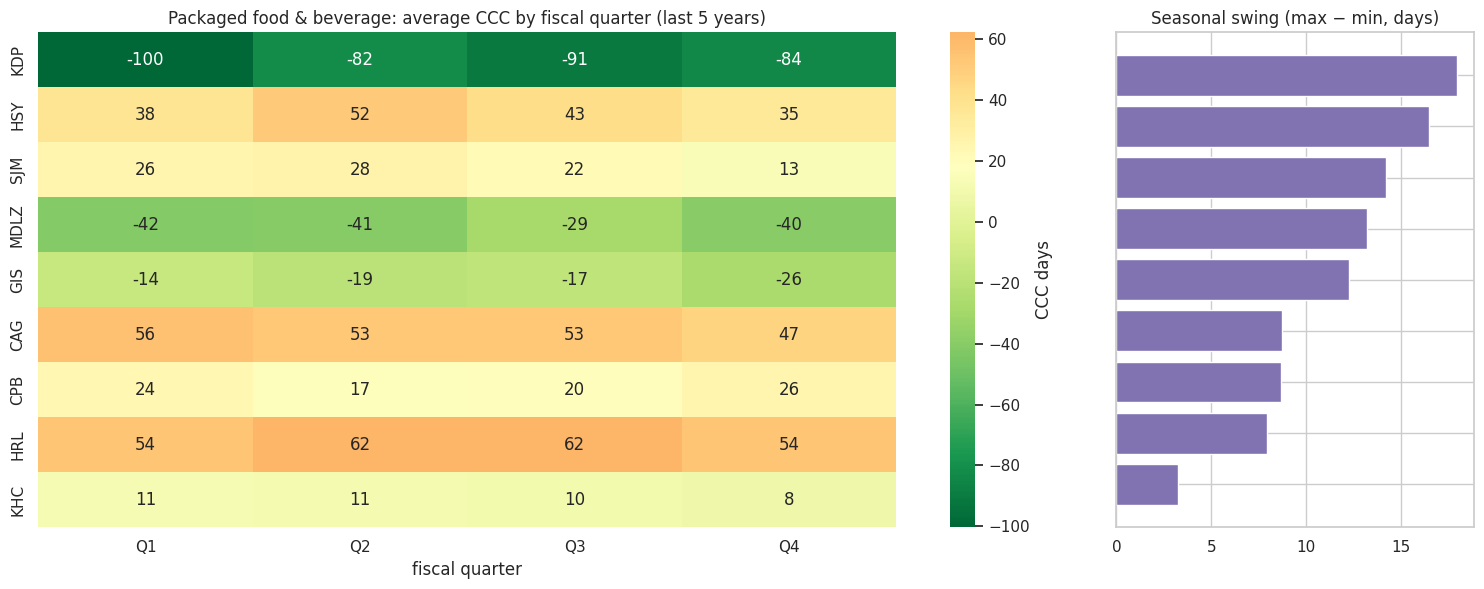

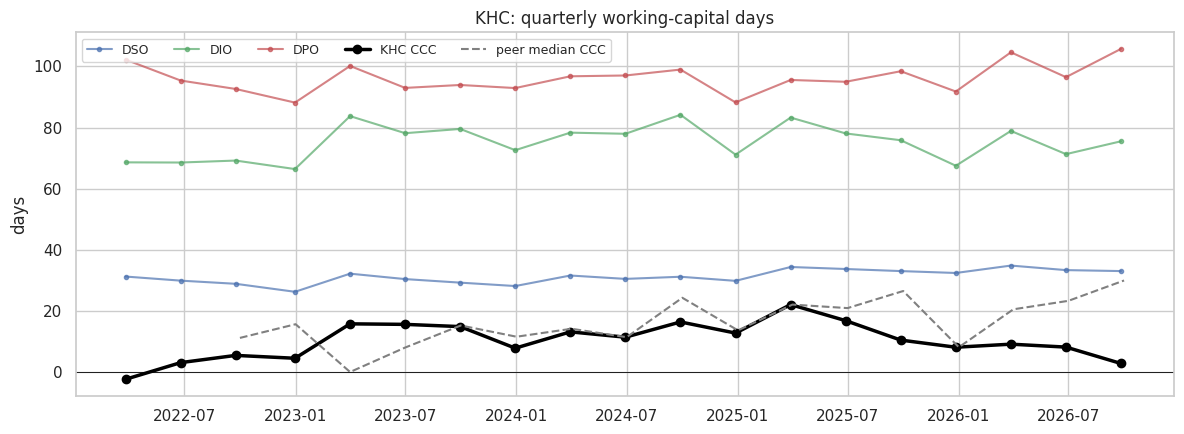

,swing_$m,swing_%_revenue
ticker,,
CAG,463.4,3.9
KDP,589.2,3.9
HSY,364.1,3.3
SJM,264.9,3.1
HRL,303.1,2.5
MDLZ,860.0,2.4
GIS,424.2,2.2
CPB,205.4,2.2
KHC,402.8,1.6


- Most seasonal: KDP (CCC swings ~18 days across the year); least seasonal: KHC (~3 days).
- KHC ties up the most cash in Q1 (CCC 11 days) and the least in Q4 (8 days).
- KHC's trade working capital swings by ~$403m within a typical year: cash that has to be funded at the peak even if the year-end balance sheet looks fine.


In [68]:
# 7b. Seasonal profile: average CCC in each fiscal quarter
prof = qp.groupby(["ticker", "fq"])["CCC"].mean().unstack().reindex(columns=[1, 2, 3, 4])
prof = prof[prof.notna().sum(axis=1) == 4]   # need all four quarters to talk about seasonality
prof["swing"] = prof.max(axis=1) - prof.min(axis=1)
prof = prof.sort_values("swing", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 0.45 * len(prof) + 2), gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(prof[[1, 2, 3, 4]], annot=True, fmt=".0f", cmap="RdYlGn_r", ax=axes[0],
            center=prof[[1, 2, 3, 4]].stack().median(), cbar_kws={"label": "CCC days"})
axes[0].set_xticklabels(["Q1", "Q2", "Q3", "Q4"]); axes[0].set_xlabel("fiscal quarter"); axes[0].set_ylabel("")
axes[0].set_title(f"{INDUSTRY}: average CCC by fiscal quarter (last {N_Q_YEARS} years)")
axes[1].barh(prof.index, prof["swing"], color="#8172B2"); axes[1].invert_yaxis()
axes[1].set_title("Seasonal swing (max − min, days)"); axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

# 7c. Target's quarterly cycle over time vs the peer median
tq = qp[qp["ticker"] == TARGET].set_index("q_end").sort_index()
grp = qp.groupby(qp["q_end"].dt.to_period("Q"))["CCC"]
peer_med = grp.median()[grp.count() >= 0.5 * qp["ticker"].nunique()]   # skip quarters only a few peers have reported yet
peer_med.index = peer_med.index.to_timestamp(how="end")
fig, ax = plt.subplots(figsize=(12, 4.5))
for col, c in [("DSO", "#4C72B0"), ("DIO", "#55A868"), ("DPO", "#C44E52")]:
    ax.plot(tq.index, tq[col], marker=".", color=c, alpha=0.7, label=col)
ax.plot(tq.index, tq["CCC"], marker="o", lw=2.5, color="black", label=f"{TARGET} CCC")
ax.plot(peer_med.index, peer_med.values, "--", color="grey", label="peer median CCC")
ax.axhline(0, color="black", lw=0.6)
ax.set_title(f"{TARGET}: quarterly working-capital days"); ax.set_ylabel("days")
ax.legend(ncol=5, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

# 7d. Seasonal cash need: how far trade working capital swings within a fiscal year
full_years = qp.groupby(["ticker", "fy"]).filter(lambda g: g["fq"].nunique() == 4)
wc_swing = (full_years.groupby(["ticker", "fy"])
            .agg(swing=("trade_wc", lambda s: s.max() - s.min()), rev=("revenue", "sum"))
            .groupby("ticker").mean())
wc_swing["swing_$m"] = wc_swing["swing"] / 1e6
wc_swing["swing_%_revenue"] = wc_swing["swing"] / wc_swing["rev"] * 100
wc_swing = wc_swing[["swing_$m", "swing_%_revenue"]].sort_values("swing_%_revenue", ascending=False)
display(wc_swing)

# takeaways
most, least = prof["swing"].idxmax(), prof["swing"].idxmin()
print(f"- Most seasonal: {most} (CCC swings ~{prof.loc[most, 'swing']:.0f} days across the year); "
      f"least seasonal: {least} (~{prof.loc[least, 'swing']:.0f} days).")
if TARGET in prof.index:
    tp = prof.loc[TARGET, [1, 2, 3, 4]]
    print(f"- {TARGET} ties up the most cash in Q{int(tp.idxmax())} (CCC {tp.max():.0f} days) "
          f"and the least in Q{int(tp.idxmin())} ({tp.min():.0f} days).")
if TARGET in wc_swing.index:
    print(f"- {TARGET}'s trade working capital swings by ~${wc_swing.loc[TARGET, 'swing_$m']:,.0f}m within a typical year: "
          f"cash that has to be funded at the peak even if the year-end balance sheet looks fine.")

## 8. Does working capital show up in cash flow and returns?

Working capital only matters if it moves the numbers investors care about. This section links the cash conversion cycle to:

- **FCF conversion** = free cash flow ÷ net income. Free cash flow = operating cash flow − capex. Cash tied up in receivables and inventory is cash that never reaches FCF, so a longer cycle should drag conversion down.
- **ROIC** = NOPAT ÷ average invested capital. NOPAT = operating income × (1 − effective tax rate); invested capital = equity + debt − cash. Working capital sits inside invested capital, so releasing it raises ROIC directly.

**Impairments are added back.** Goodwill and intangible write-downs are non-cash, one-off accounting charges (Kraft Heinz, Conagra and Smucker's all took big ones recently). Left in, they turn ROIC negative and make FCF ÷ net income meaningless, so operating income and net income are measured before them.

Three views: across peers in the latest year, within each company over time (does a year where the cycle lengthens also see weaker conversion?), and a what-if for the target.

In [69]:
# 8a. Pull cash-flow, income and capital data (same 10-K source, same fiscal years)
RET_TAGS = {
    "ocf":         ["NetCashProvidedByUsedInOperatingActivities", "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations"],
    "capex":       ["PaymentsToAcquirePropertyPlantAndEquipment", "PaymentsToAcquireProductiveAssets"],
    "net_income":  ["NetIncomeLoss", "ProfitLoss"],
    "op_income":   ["OperatingIncomeLoss"],
    "pretax":      ["IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest",
                    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesMinorityInterestAndIncomeLossFromEquityMethodInvestments"],
    "tax":         ["IncomeTaxExpenseBenefit"],
    "equity":      ["StockholdersEquity", "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest"],
    "lt_debt":     ["LongTermDebt", "LongTermDebtAndCapitalLeaseObligationsIncludingCurrentMaturities"],
    "lt_debt_nc":  ["LongTermDebtNoncurrent", "LongTermDebtAndCapitalLeaseObligations"],
    "lt_debt_cur": ["LongTermDebtCurrent", "LongTermDebtAndCapitalLeaseObligationsCurrent"],
    "st_debt":     ["ShortTermBorrowings", "CommercialPaper", "OtherShortTermBorrowings"],
    "cash":        ["CashAndCashEquivalentsAtCarryingValue", "CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalents"],
    # non-cash write-downs, added back so one-off accounting charges don't swamp the comparison
    "imp_combined": ["GoodwillAndIntangibleAssetImpairment"],
    "imp_goodwill": ["GoodwillImpairmentLoss"],
    "imp_intang":   ["ImpairmentOfIntangibleAssetsIndefinitelivedExcludingGoodwill", "ImpairmentOfIntangibleAssetsExcludingGoodwill"],
}
RET_FLOWS = {"ocf", "capex", "net_income", "op_income", "pretax", "tax", "imp_combined", "imp_goodwill", "imp_intang"}

def ranked(cf, tags, flow):
    vals = {}
    for tag in tags:
        for d, v in tag_series(cf, tag, flow).items():
            vals.setdefault(d, v)
    return pd.Series(vals, dtype=float)

rrows = []
for t in m["ticker"].unique():
    ends = raw.loc[raw["ticker"] == t, "fy_end"].values
    d = pd.DataFrame({k: ranked(facts[t], tags, k in RET_FLOWS).reindex(ends).values for k, tags in RET_TAGS.items()})
    d["fy_end"], d["ticker"] = ends, t
    rrows.append(d)
rd = pd.concat(rrows, ignore_index=True)

# invested capital = equity + debt - cash
debt = rd["lt_debt"].fillna(rd["lt_debt_nc"].fillna(0) + rd["lt_debt_cur"].fillna(0)) + rd["st_debt"].fillna(0)
rd["invested_capital"] = rd["equity"] + debt - rd["cash"].fillna(0)
rd["impairment"] = rd["imp_combined"].fillna(rd["imp_goodwill"].fillna(0) + rd["imp_intang"].fillna(0))
pretax_adj = rd["pretax"] + rd["impairment"]
tax_rate = (rd["tax"] / pretax_adj).where(pretax_adj > 0).clip(0, 0.4).fillna(0.21)   # fallback: US statutory 21%
rd["nopat"] = (rd["op_income"] + rd["impairment"]) * (1 - tax_rate)                   # operating profit before impairments
rd["adj_net_income"] = rd["net_income"] + rd["impairment"]
rd["fcf"] = rd["ocf"] - rd["capex"].fillna(0)

ret = m.merge(rd, on=["ticker", "fy_end"], how="left").sort_values(["ticker", "fy"])
ret["avg_ic"] = ret.groupby("ticker")["invested_capital"].transform(lambda s: (s + s.shift(1)) / 2)
ret["ROIC"] = (ret["nopat"] / ret["avg_ic"] * 100).where(ret["avg_ic"] > 0)          # meaningless if capital <= 0
ret["FCF_conv"] = (ret["fcf"] / ret["adj_net_income"] * 100).where(ret["adj_net_income"] > 0)
ret["FCF_margin"] = ret["fcf"] / ret["revenue"] * 100
ret["d_CCC"] = ret.groupby("ticker")["CCC"].diff()

lr = ret[ret["fy"] == LATEST].set_index("ticker")
tbl = lr[["CCC", "FCF_margin", "FCF_conv", "ROIC"]].assign(invested_capital_bn=lr["invested_capital"] / 1e9)
tbl = tbl.rename(columns={"FCF_margin": "FCF_margin_%", "FCF_conv": "FCF_conversion_%", "ROIC": "ROIC_%"})
print(f"Cash flow and returns, FY{LATEST}:")
display(tbl.sort_values("CCC"))
missing_ret = tbl[tbl[["FCF_conversion_%", "ROIC_%"]].isna().any(axis=1)].index.tolist()
imp = lr.loc[lr["impairment"] > 0, "impairment"] / 1e6
if len(imp):
    print("Impairments added back in FY%d ($m):" % LATEST, imp.round(0).to_dict())
if missing_ret:
    print("Missing or not meaningful (negative income or capital, or an unmapped tag):", missing_ret)

Cash flow and returns, FY2025:


,CCC,FCF_margin_%,FCF_conversion_%,ROIC_%,invested_capital_bn
ticker,,,,,
MDLZ,-38.1,8.4,132.0,6.0,44.8
KDP,-35.9,9.1,69.8,7.5,38.4
GIS,-24.3,8.8,97.8,9.6,20.5
PEP,-6.5,8.2,75.0,20.9,57.6
KO,5.7,11.0,37.5,19.6,67.3
KHC,10.8,14.7,105.8,6.5,60.3
SJM,21.8,12.8,140.5,9.3,12.4
CPB,24.4,6.9,90.6,9.7,10.6
HSY,30.2,15.6,204.9,11.6,9.1


Impairments added back in FY2025 ($m): {'CAG': 2930.0, 'CPB': 176.0, 'GIS': 1750.0, 'HRL': 71.0, 'HSY': 6.0, 'KDP': 78.0, 'KHC': 9306.0, 'KO': 1033.0, 'PEP': 1993.0, 'SJM': 962.0}


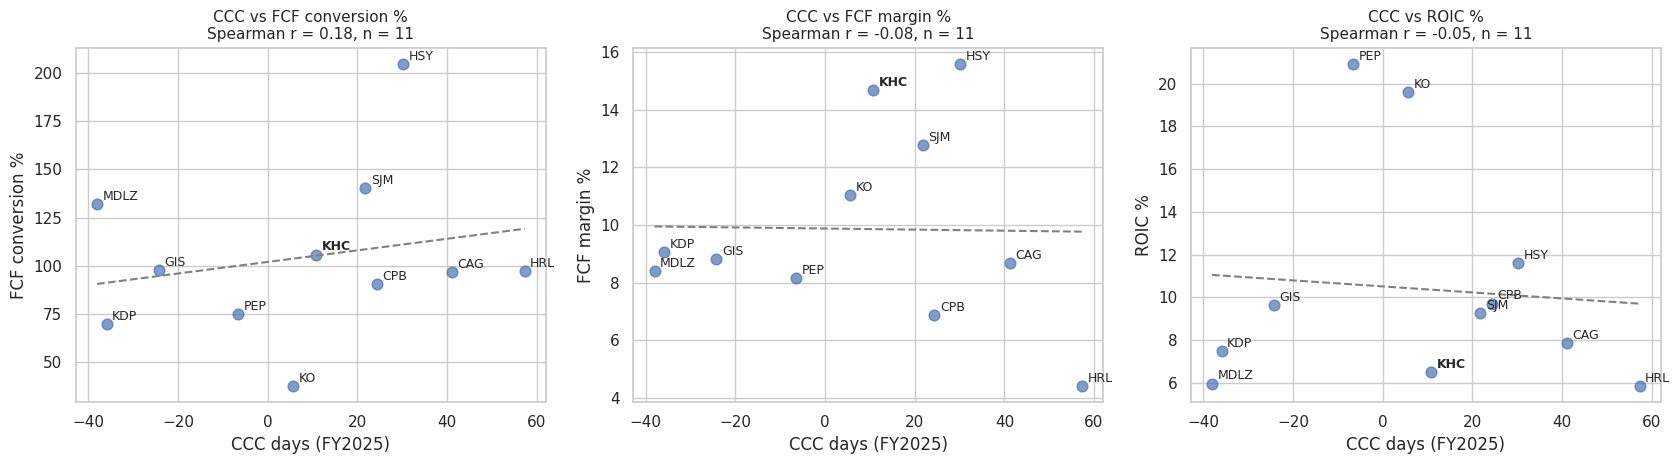

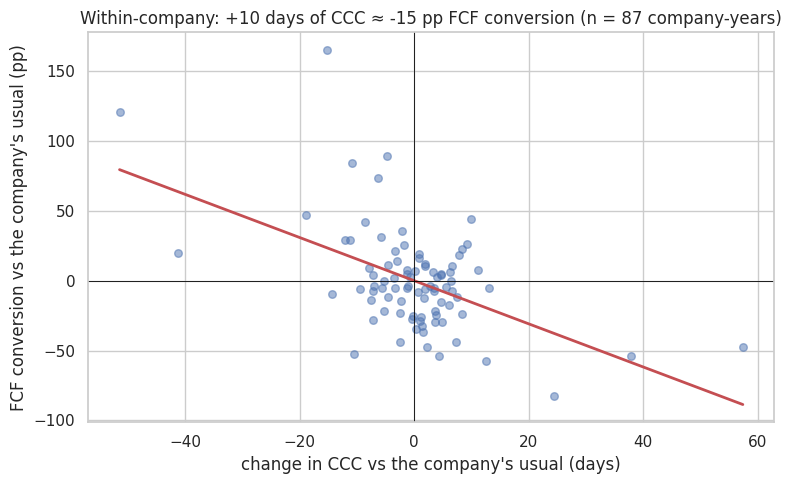

KHC, FY2025:
- Releasing $684m of working capital lifts ROIC (year-end capital) from 6.9% to 7.0% (+0.08 pp), with no change in profit.
- It is a one-off cash inflow worth 19% of a year's free cash flow (FY2025 FCF $3,661m).
- Across peers, CCC vs FCF conversion %: Spearman r = 0.18 (no clear link).
- Across peers, CCC vs FCF margin %: Spearman r = -0.08 (no clear link).
- Across peers, CCC vs ROIC %: Spearman r = -0.05 (no clear link).
- Within companies over time, each +10 days of CCC goes with -15 pp FCF conversion that year.


In [70]:
# 8b. Across peers: does a shorter cycle go with better conversion and returns?
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
cross = {}
for ax, col, lab in [(axes[0], "FCF_conv", "FCF conversion %"), (axes[1], "FCF_margin", "FCF margin %"), (axes[2], "ROIC", "ROIC %")]:
    d = lr[["CCC", col]].dropna()
    ax.scatter(d["CCC"], d[col], s=60, alpha=0.7, color="#4C72B0")
    for t, r in d.iterrows():
        ax.annotate(t, (r["CCC"], r[col]), fontsize=9, xytext=(4, 3), textcoords="offset points",
                    fontweight="bold" if t == TARGET else "normal")
    if len(d) >= 4:
        b, a = np.polyfit(d["CCC"], d[col], 1)
        xs = np.linspace(d["CCC"].min(), d["CCC"].max(), 50)
        ax.plot(xs, a + b * xs, "--", color="grey")
        cross[lab] = d["CCC"].corr(d[col], method="spearman")
        ax.set_title(f"CCC vs {lab}\nSpearman r = {cross[lab]:.2f}, n = {len(d)}", fontsize=11)
    ax.set_xlabel(f"CCC days (FY{LATEST})"); ax.set_ylabel(lab)
plt.tight_layout(); plt.show()

# 8c. Within each company over time: when the cycle lengthens, does conversion weaken?
p = ret.dropna(subset=["d_CCC", "FCF_conv"])
p = p[p["FCF_conv"].between(-100, 300)]          # drop years where tiny/odd net income makes the ratio meaningless
x = p["d_CCC"] - p.groupby("ticker")["d_CCC"].transform("mean")        # demean per company = compare each company to itself
y = p["FCF_conv"] - p.groupby("ticker")["FCF_conv"].transform("mean")
beta = (x * y).sum() / (x * x).sum() if len(p) > 5 else np.nan
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.5, s=30)
xs = np.linspace(x.min(), x.max(), 50); ax.plot(xs, beta * xs, color="#C44E52", lw=2)
ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("change in CCC vs the company's usual (days)"); ax.set_ylabel("FCF conversion vs the company's usual (pp)")
ax.set_title(f"Within-company: +10 days of CCC ≈ {beta * 10:+.0f} pp FCF conversion (n = {len(p)} company-years)")
plt.tight_layout(); plt.show()

# 8d. What-if for the target: release the cash from section 5
tr = ret[(ret["ticker"] == TARGET) & (ret["fy"] == LATEST)].iloc[0]
release = total * 1e6
print(f"{TARGET}, FY{LATEST}:")
if pd.notna(tr["invested_capital"]) and tr["invested_capital"] > release and pd.notna(tr["nopat"]) and tr["nopat"] > 0:
    roic_now = tr["nopat"] / tr["invested_capital"] * 100
    roic_new = tr["nopat"] / (tr["invested_capital"] - release) * 100
    print(f"- Releasing ${total:,.0f}m of working capital lifts ROIC (year-end capital) from {roic_now:.1f}% to {roic_new:.1f}% "
          f"({roic_new - roic_now:+.2f} pp), with no change in profit.")
if pd.notna(tr["fcf"]) and tr["fcf"] > 0:
    print(f"- It is a one-off cash inflow worth {release / tr['fcf'] * 100:.0f}% of a year's free cash flow (FY{LATEST} FCF ${tr['fcf'] / 1e6:,.0f}m).")
for lab, r_ in cross.items():
    print(f"- Across peers, CCC vs {lab}: Spearman r = {r_:.2f} "
          f"({'shorter cycle goes with higher ' + lab if r_ < -0.3 else 'longer cycle goes with higher ' + lab if r_ > 0.3 else 'no clear link'}).")
if pd.notna(beta):
    print(f"- Within companies over time, each +10 days of CCC goes with {beta * 10:+.0f} pp FCF conversion that year.")

## 9. Auto-generated takeaways

In [71]:
best, worst = latest["CCC"].idxmin(), latest["CCC"].idxmax()
first = m.groupby("ticker")["fy"].min()
chg = {tk: m[(m.ticker == tk) & (m.fy == LATEST)]["CCC"].iloc[0] - m[(m.ticker == tk) & (m.fy == first[tk])]["CCC"].iloc[0]
       for tk in latest.index}
chg = pd.Series(chg).sort_values()
biggest_lever = opp.loc[opp["cash_release_$m"].idxmax(), "lever"]

print(f"- Best-in-class CCC in FY{LATEST}: {best} at {latest.loc[best,'CCC']:.0f} days; worst: {worst} at {latest.loc[worst,'CCC']:.0f} days.")
print(f"- Peer median CCC: {latest['CCC'].median():.0f} days (DSO {latest['DSO'].median():.0f}, DIO {latest['DIO'].median():.0f}, DPO {latest['DPO'].median():.0f}).")
print(f"- Most improved since start of window: {chg.index[0]} ({chg.iloc[0]:+.0f} days); most deteriorated: {chg.index[-1]} ({chg.iloc[-1]:+.0f} days).")
print(f"- {TARGET}'s biggest lever vs peer {BENCHMARK}: {biggest_lever}; total opportunity ≈ ${total:,.0f}m.")
print(f"- {sum(latest['CCC'] < 0)} of {len(latest)} companies run a negative CCC, i.e. suppliers fund part of their operations.")

- Best-in-class CCC in FY2025: MDLZ at -38 days; worst: HRL at 57 days.
- Peer median CCC: 11 days (DSO 26, DIO 71, DPO 93).
- Most improved since start of window: CPB (-41 days); most deteriorated: KHC (+30 days).
- KHC's biggest lever vs peer median: Receivables (collect faster); total opportunity ≈ $684m.
- 4 of 11 companies run a negative CCC, i.e. suppliers fund part of their operations.


## 10. Export

In [72]:
with pd.ExcelWriter("working_capital_benchmark.xlsx") as xw:
    m.to_excel(xw, sheet_name="metrics_by_year", index=False)
    view.to_excel(xw, sheet_name=f"peer_table_FY{LATEST}")
    opp.to_excel(xw, sheet_name=f"opportunity_{TARGET}", index=False)
    opp_all.to_excel(xw, sheet_name="opportunity_all")
    used.to_excel(xw, sheet_name="xbrl_tags_used")
    qp.to_excel(xw, sheet_name="quarterly", index=False)
    prof.to_excel(xw, sheet_name="seasonal_profile")
    ret.to_excel(xw, sheet_name="cash_flow_and_roic", index=False)
print("Saved working_capital_benchmark.xlsx (Colab: Files panel on the left -> download)")

Saved working_capital_benchmark.xlsx (Colab: Files panel on the left -> download)


## 11. Limitations (say these before an interviewer does)

- **Reported tags aren't always comparable.** Some receivables lines include non-trade items; some payables include accruals. The tag log in section 2 makes this visible.
- **Supply-chain finance** (reverse factoring) inflates DPO for some companies and is only partly disclosed in footnotes.
- **Receivables factoring/securitisation** lowers DSO without changing customer behaviour.
- **Fiscal year-ends differ** (GIS ends in May, most others in December), so seasonal inventory peaks fall in different places.
- **M&A** (e.g. KDP's merger, KHC's divestitures) causes jumps in averages; the year after a big deal deserves a footnote.
- **Industries differ structurally.** Retailers and airlines often run negative cycles (customers pay upfront); machinery and pharma carry long inventory. Only compare within a peer group, never across industries.
- **Quarterly data is rougher.** Q4 flows are derived (full year minus Q1–Q3), quarter-end balances are used rather than averages, and the accrued-payables exclusion is only applied to the annual view.
- **ROIC and FCF are simplified.** Invested capital = equity + debt − cash (leases, goodwill and pension items not adjusted); the tax rate is the reported effective rate (21% fallback). Correlations across ~10 companies are suggestive, not proof.
- **Benchmarking ≠ target-setting.** A company with a different channel mix (e.g. more DSD, more emerging markets) can have a legitimately different cycle.

## 12. Ideas to extend it

- Turn section 5 into a Streamlit app where the user picks the target and benchmark